*Elena Cascone*

*Antonio Sirignano*

# Pulizia dati stazione meteo + sonde suolo — Progetto irrigazione vite

**Obiettivo del progetto:** decidere, in base alle condizioni meteo, **quando**, **quanto** e **per quanto tempo** irrigare la vite, confrontando una zona irrigata e una non irrigata.

**Obiettivo di questo notebook:** partire dal file grezzo della centralina (`history_last_4_years_irr_noirr_28_07.csv`) e arrivare a un dataset pulito, documentato e pronto per la fase di modellazione (bilancio idrico + calibrazione).



## 0. Setup

In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

IN_PATH = "/Users/elecas/Documents/TIROCINIO/history_last_4_years_irr_noirr_28_07.csv"


## 1. Caricamento ed esplorazione iniziale

Prima di pulire qualunque cosa, guardiamo la forma grezza dei dati: quante righe, quali colonne, quanti valori mancanti. Questo è il passaggio che ci ha permesso di scoprire la struttura reale del dataset (due zone nella stessa tabella, sonde diverse con disponibilità diverse).

In [2]:
df = pd.read_csv(IN_PATH)
print("Righe:", len(df), " Colonne:", df.shape[1])
df.head(3)

Righe: 55787  Colonne: 45


,station_id,ts,irrigated,water_potential_last,direct_reading_last,temp_resistance_last,wind_speed_avg,uv_dose,wind_speed_hi,wind_dir_of_hi,wind_chill,solar_rad_hi,deg_days_heat,thw_index,bar,hum_out,uv_index_hi,temp_out,temp_out_lo,wet_bulb,temp_out_hi,solar_rad_avg,bar_alt,wind_run,solar_energy,dew_point_out,wind_dir_of_prevail,et,air_density,rainfall_in,heat_index_out,thsw_index,rainfall_mm,night_cloud_cover,deg_days_cool,rain_rate_hi_in,uv_index_avg,emc,rain_rate_hi_mm,abs_press,salinity_last_1,moist_soil_last_1,temp_last_1,bar_trend_3_hr,pressure_last
0,90411,2023-04-13 13:00:00,1.0,NaN,NaN,NaN,13.0,NaN,24.0,11.0,59.84067,786.0,0.041667,59.060673,29.572,64.0,NaN,64.0,63.8,55.507202,64.4,655.0,29.572,13.0,56.358630,51.574596,10.0,0.018,0.070477,0.0,63.22,69.0,0.0,0.0,0.0,0.0,NaN,11.770,0.0,28.210167,NaN,NaN,NaN,-0.001,29.572
1,90411,2023-04-13 14:00:00,0.0,NaN,NaN,NaN,12.0,NaN,26.0,9.0,60.79224,763.0,0.025000,59.732240,29.559,60.0,NaN,64.4,63.6,54.662464,64.9,549.0,29.559,12.0,47.237995,50.207966,10.0,0.015,0.070440,0.0,63.34,66.0,0.0,0.0,0.0,0.0,NaN,11.062,0.0,28.197653,NaN,NaN,NaN,-0.020,29.559
2,90411,2023-04-13 14:00:00,1.0,NaN,NaN,NaN,12.0,NaN,26.0,9.0,60.79224,763.0,0.025000,59.732240,29.559,60.0,NaN,64.4,63.6,54.662464,64.9,549.0,29.559,12.0,47.237995,50.207966,10.0,0.015,0.070440,0.0,63.34,66.0,0.0,0.0,0.0,0.0,NaN,11.062,0.0,28.197653,NaN,NaN,NaN,-0.020,29.559


In [3]:
df.isnull().sum().sort_values(ascending=False).head(10)

uv_index_hi             55787
uv_index_avg            55787
uv_dose                 55787
water_potential_last    51197
direct_reading_last     51197
temp_resistance_last    51197
wind_dir_of_hi           1621
wind_dir_of_prevail      1621
emc                        27
pressure_last              16
dtype: int64

## 2. Parsing dei tipi e ordinamento

- `ts` va convertito da stringa a datetime, altrimenti pandas lo tratta come testo.
- `irrigated` è la variabile che distingue le due zone (1 = irrigata, 0 = non irrigata): la forziamo a intero nullable (`Int8`) invece di float, perché è categoriale, non una misura.
- Ordiniamo per zona e timestamp per avere serie temporali pulite in entrambi i gruppi.

In [4]:
df["ts"] = pd.to_datetime(df["ts"])
df["irrigated"] = df["irrigated"].astype("Int8")
df = df.sort_values(["irrigated", "ts"]).reset_index(drop=True)

n_start = len(df)
print("Periodo:", df["ts"].min(), "->", df["ts"].max())
print(df["irrigated"].value_counts())

Periodo: 2023-04-13 13:00:00 -> 2026-07-28 06:00:00
irrigated
0    28173
1    27614
Name: count, dtype: Int64


## 3. Rimozione delle colonne completamente vuote

`uv_dose`, `uv_index_hi`, `uv_index_avg` risultano `NaN` su tutte le righe: il sensore UV non è mai stato installato o non ha mai loggato dati. Colonne al 100% vuote non portano informazione e vanno tolte subito, altrimenti "sporcano" ogni controllo successivo sui missing values.

In [5]:
empty_cols = [c for c in df.columns if df[c].isnull().all()]
print("Colonne rimosse perché vuote:", empty_cols)
df = df.drop(columns=empty_cols)

Colonne rimosse perché vuote: ['uv_dose', 'uv_index_hi', 'uv_index_avg']


## 4. Unità di misura: eliminare le ridondanze e portare tutto al metrico

La centralina fornisce alcune grandezze in doppio formato (es. pioggia in `mm` e in `in`) e altre solo in imperiale (temperatura in °F, vento in mph, pressione in inHg). Qui convertiamo tutto in unità metriche e teniamo **una sola versione** di ogni grandezza.

In [6]:
# Pioggia: teniamo solo mm
for a, b in [("rainfall_in", "rainfall_mm"), ("rain_rate_hi_in", "rain_rate_hi_mm")]:
    if a in df.columns and b in df.columns:
        df = df.drop(columns=[a])

# Temperatura: °F -> °C
FAHRENHEIT_TEMP_COLS = [
    "wind_chill", "thw_index", "temp_out", "temp_out_lo", "wet_bulb",
    "temp_out_hi", "dew_point_out", "heat_index_out", "thsw_index",
    "temp_last_1",
]
for c in FAHRENHEIT_TEMP_COLS:
    if c in df.columns:
        df[c + "_c"] = (df[c] - 32) * 5 / 9
        df = df.drop(columns=[c])

# Vento: mph -> km/h
for c in ["wind_speed_avg", "wind_speed_hi", "wind_run"]:
    if c in df.columns:
        df[c + "_kmh"] = df[c] * 1.60934
        df = df.drop(columns=[c])

# Pressione: inHg -> hPa
for c in ["bar", "bar_alt", "abs_press", "pressure_last"]:
    if c in df.columns:
        df[c + "_hpa"] = df[c] * 33.8639
        df = df.drop(columns=[c])

# et: pollici -> mm
df["et_mm"] = df["et"] * 25.4
df = df.drop(columns=["et"])

# air_density: slugs/ft^3 -> kg/m^3
df["air_density_kgm3"] = df["air_density"] * 16.0185   # lb/ft^3 -> kg/m^3
df = df.drop(columns=["air_density"])

# bar_trend_3_hr: inHg -> hPa (stessa costante usata per bar/abs_press/pressure_last)
df["bar_trend_3_hr_hpa"] = df["bar_trend_3_hr"] * 33.8639
df = df.drop(columns=["bar_trend_3_hr"])

print("Colonne dopo la conversione unità:", df.shape[1])


Colonne dopo la conversione unità: 40


## 5. La sonda suolo "legacy" non è zona-specifica

Controllo importante: `salinity_last_1` e `moist_soil_last_1` sono misure del suolo, ma verificando i valori allo stesso timestamp tra le due zone risultano **identici**. Questo significa che è un'unica sonda condivisa , replicata su entrambe le righe, **non** è utile per confrontare irrigato vs non irrigato.

In [7]:
common_ts = df.groupby("ts")["irrigated"].nunique()
both = common_ts[common_ts == 2].index

check = df[df["ts"].isin(both)].pivot_table(index="ts", columns="irrigated", values="moist_soil_last_1")
check["diff"] = check[0] - check[1]
print("Righe con differenza != 0 tra le due zone:", (check["diff"] != 0).sum(), "su", len(check.dropna()))
check.head()

Righe con differenza != 0 tra le due zone: 0 su 27606


irrigated,0,1,diff
ts,,,
2023-04-13 15:00:00,34.15,34.15,0.0
2023-04-13 16:00:00,34.45,34.45,0.0
2023-04-13 17:00:00,34.55,34.55,0.0
2023-04-13 18:00:00,34.60,34.60,0.0
2023-04-13 19:00:00,34.70,34.70,0.0


## 6. La sonda Watermark (`water_potential_last`) È zona-specifica

Qui invece i valori **differiscono** tra le due zone, ed è fisicamente coerente: il potenziale idrico del suolo (in centibar, più negativo = terreno più secco) è più alto (meno negativo) nella zona irrigata. È l'unica prova diretta nei dati che l'irrigazione ha effetto — ma è disponibile solo su una finestra recente e diversa per zona (sonda installata in momenti diversi nelle due zone).

In [8]:
watermark_cols = [c for c in ["water_potential_last", "direct_reading_last", "temp_resistance_last"] if c in df.columns]
df["watermark_available"] = df[watermark_cols].notnull().any(axis=1)

print(df[df["watermark_available"]].groupby("irrigated")["ts"].agg(["min", "max", "count"]))
print()
print("Media water_potential_last per zona (cbar, piu' vicino a 0 = terreno piu' umido):")
print(df.groupby("irrigated")["water_potential_last"].mean())

                          min                 max  count
irrigated                                               
0         2026-05-12 17:00:00 2026-07-28 06:00:00   1838
1         2026-03-09 10:00:00 2026-07-28 06:00:00   2752

Media water_potential_last per zona (cbar, piu' vicino a 0 = terreno piu' umido):
irrigated
0   -7.363482
1   -1.977108
Name: water_potential_last, dtype: float64


## 7. Controlli di range fisico

Valori fuori dal range plausibile (es. umidità relativa oltre 0-100%, pioggia negativa, potenziale idrico positivo) vengono impostati a `NaN` invece di eliminare l'intera riga: così non perdiamo le altre variabili misurate correttamente nella stessa ora.

In [9]:
# limiti fisici plausibili — non tarati sul clima locale, ma su estremi assoluti
# noti (record mondiali, range di funzionamento del sensore): servono a beccare
# errori grossolani di sensore/trasmissione, non a fare QC climatico fine
PHYSICAL_RANGES = {
    # temperatura e derivati: -40/+55°C copre ampiamente gli estremi italiani
    # e lascia margine, ma esclude errori di sensore/unità (es. residui in °F)
    "wind_chill_c": (-40, 55), "thw_index_c": (-40, 55), "temp_out_c": (-40, 55),
    "temp_out_lo_c": (-40, 55), "wet_bulb_c": (-40, 55), "temp_out_hi_c": (-40, 55),
    "dew_point_out_c": (-40, 55), "heat_index_out_c": (-40, 55),
    "thsw_index_c": (-40, 55), "temp_last_1_c": (-40, 55),

    "hum_out": (0, 100),                       # % relativa, per definizione
    "night_cloud_cover": (0, 1),               # frazione di cielo coperto

    "wind_speed_avg_kmh": (0, 300), "wind_speed_hi_kmh": (0, 300),
    "wind_run_kmh": (0, 300),                  # oltre 300 km/h fuori scala anemometro
    "wind_dir_of_hi": (0, 15), "wind_dir_of_prevail": (0, 15),  # codice rosa venti 16 punte, non gradi

    "solar_rad_hi": (0, 1500), "solar_rad_avg": (0, 1500),      # W/m², costante solare ~1361 W/m²
    "solar_energy": (0, 150),                  # langley/ora coerenti con 1500 W/m² sostenuti 1h

    "et_mm": (0, 2),                           # ET oraria estrema, raramente oltre 1-1.5 mm/h
    "air_density_kgm3": (0.8, 1.5),            # variazione per quota/temperatura
    "bar_trend_3_hr_hpa": (-20, 20),           # variazione barometrica estrema in 3h

    "rainfall_mm": (0, 400), "rain_rate_hi_mm": (0, 400),  # record mondiale ~305mm/h

    "bar_hpa": (870, 1085), "bar_alt_hpa": (870, 1085),
    "abs_press_hpa": (870, 1085), "pressure_last_hpa": (870, 1085),  # estremi record mondiali

    "emc": (0, 40),                            # equilibrium moisture content, %
    "salinity_last_1": (0, 30),                # conducibilità elettrica suolo, dS/m
    "moist_soil_last_1": (0, 60),              # contenuto idrico volumetrico suolo, % — raramente oltre 55-60% anche saturo

    "water_potential_last": (-200, 0),         # range operativo dichiarato del sensore Watermark
}

In [10]:
IQR_COLS = ["direct_reading_last", "temp_resistance_last"]

def iqr_bounds(series, k=3):
    # k=3 (non 1.5) perché qui l'obiettivo è beccare errori grossolani,
    # non fare outlier detection fine: 1.5 sarebbe troppo aggressivo su un
    # sensore che già conosciamo poco
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

In [11]:
range_report = []

for col, (lo, hi) in PHYSICAL_RANGES.items():
    mask = (df[col] < lo) | (df[col] > hi)
    n_flag = mask.sum()
    df.loc[mask, col] = np.nan
    range_report.append({"variabile": col, "metodo": "fisico", "min": lo, "max": hi, "n_flag": n_flag})

for col in IQR_COLS:
    lo, hi = iqr_bounds(df[col].dropna())
    mask = (df[col] < lo) | (df[col] > hi)
    n_flag = mask.sum()
    df.loc[mask, col] = np.nan
    range_report.append({"variabile": col, "metodo": "statistico (IQR k=3)", "min": round(lo, 2), "max": round(hi, 2), "n_flag": n_flag})

range_report = pd.DataFrame(range_report)
print(range_report)

               variabile                metodo      min      max  n_flag
0           wind_chill_c                fisico   -40.00    55.00       0
1            thw_index_c                fisico   -40.00    55.00       0
2             temp_out_c                fisico   -40.00    55.00       0
3          temp_out_lo_c                fisico   -40.00    55.00       0
4             wet_bulb_c                fisico   -40.00    55.00       0
5          temp_out_hi_c                fisico   -40.00    55.00       0
6        dew_point_out_c                fisico   -40.00    55.00       0
7       heat_index_out_c                fisico   -40.00    55.00       0
8           thsw_index_c                fisico   -40.00    55.00       0
9          temp_last_1_c                fisico   -40.00    55.00       0
10               hum_out                fisico     0.00   100.00       0
11     night_cloud_cover                fisico     0.00     1.00       0
12    wind_speed_avg_kmh                fisico     

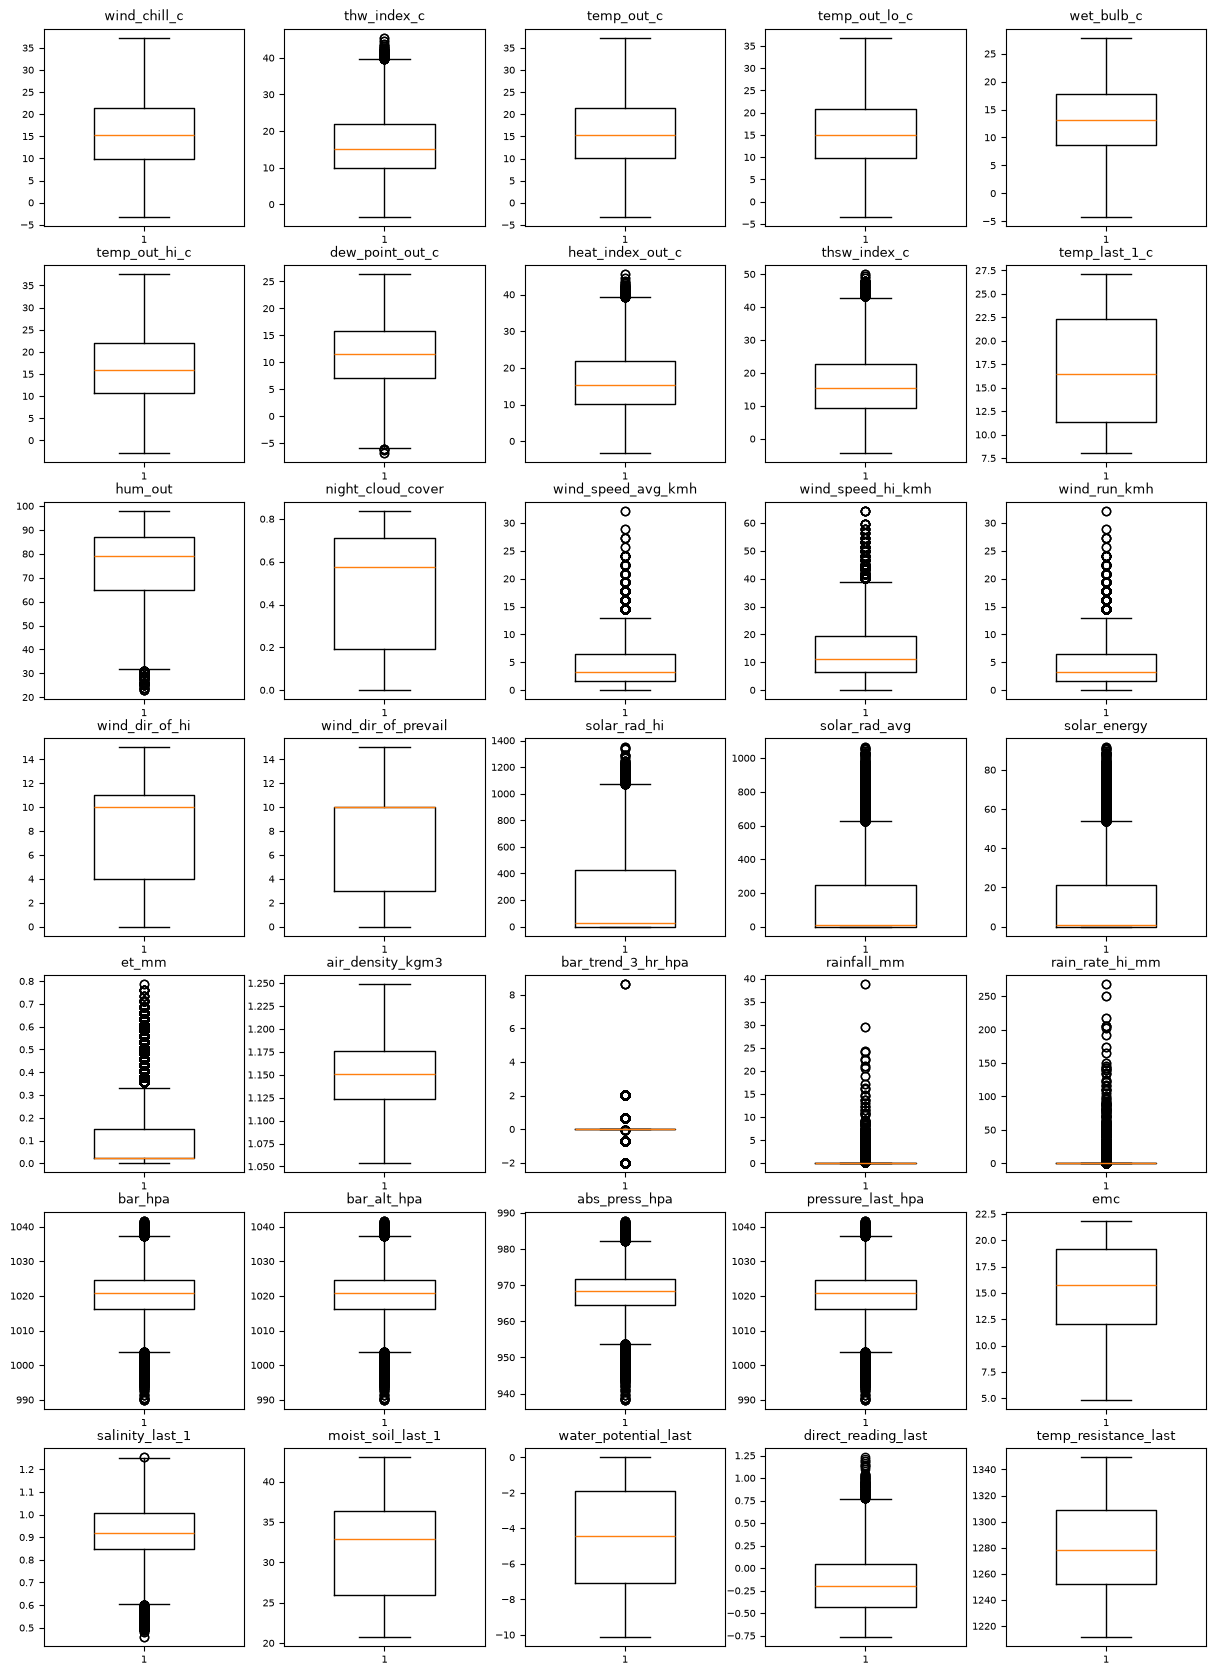

In [12]:
import matplotlib.pyplot as plt

plot_cols = list(PHYSICAL_RANGES.keys()) + IQR_COLS

n = len(plot_cols)
ncols = 5
nrows = int(np.ceil(n / ncols))  # arrotondo per eccesso, l'ultima riga puo' restare incompleta

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3, nrows * 3))
axes = axes.flatten()  # axes normalmente è una matrice 2D (nrows x ncols); la appiattisco
                        # per poterci scorrere sopra con un semplice indice i


for i, col in enumerate(plot_cols):
    ax = axes[i]
    ax.boxplot(df[col].dropna(), orientation="vertical", widths=0.5)  # dropna: boxplot non accetta NaN
    ax.set_title(col, fontsize=9)
    ax.tick_params(axis="both", labelsize=7)  # font piccolo, altrimenti le etichette si sovrappongono

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.show()

Indaghiamo meglio 'bar_trend_3_hr_hpa' perchè non si riesce a leggere bene:

In [13]:
print(df['bar_trend_3_hr_hpa'].value_counts().head(10))

bar_trend_3_hr_hpa
 0.000000    28883
 0.677278    12448
-0.677278    12158
-2.031834     1136
 2.031834     1105
-0.033864       37
 8.635295        4
Name: count, dtype: int64


I valori assunti dalla variabile sono solo questi 7 possibili, quindi può essere che la variabile sia categoriale e vada ricodificata, inoltre 0, ±0,02, ±0,06 inHg/3h sono esattamente i 5 codici standard Davis per il trend barometrico, gli ultimi due non appartengono allo schema.


In [14]:
# ricostruisco i valori originali in inHg (stessa costante usata per la conversione in hPa)
raw = (df["bar_trend_3_hr_hpa"] / 33.8639).round(4)

# i 5 codici standard Davis per il trend barometrico a 3h, in ordine crescente
BAR_TREND_CODES = {
    -0.06: "in rapida discesa",
    -0.02: "in lenta discesa",
     0.00: "stabile",
     0.02: "in lenta salita",
     0.06: "in rapida salita",
}

# mappo i valori noti; quello che non corrisponde a nessun codice standard
# (i 41 casi -0.001 e 0.255) diventa esplicitamente "non_standard", non NaN silenzioso:
# così restano visibili e tracciabili invece di sparire nel missing generico
df["bar_trend_cat"] = raw.map(BAR_TREND_CODES).fillna("non_standard")

# categoria ordinata: ha senso per un eventuale modello che i 5 livelli standard
# abbiano un ordine (discesa rapida < discesa lenta < stabile < salita lenta < salita rapida),
# mentre "non_standard" resta fuori dall'ordine, non è un sesto livello di intensità
cat_order = ["in rapida discesa", "in lenta discesa", "stabile", "in lenta salita", "in rapida salita", "non_standard"]
df["bar_trend_cat"] = pd.Categorical(df["bar_trend_cat"], categories=cat_order, ordered=True)

print(df["bar_trend_cat"].value_counts())

bar_trend_cat
stabile              28883
in lenta salita      12448
in lenta discesa     12158
in rapida discesa     1136
in rapida salita      1105
non_standard            57
Name: count, dtype: int64


Tolgo la colonna numerica bar_trend_3_hr_hpa e tengo solo bar_trend_cat

In [15]:

df = df.drop(columns=["bar_trend_3_hr_hpa"])  # via la versione numerica, fuorviante come continua


## 8. Continuità temporale: dove sono i buchi nella serie?

Confrontiamo le ore effettivamente presenti con il calendario orario completo del periodo. Le ore mancanti **non vengono riempite artificialmente** (niente forward-fill/interpolazione automatica): un buco reale nella serie (es. centralina spenta) non deve diventare "pioggia zero" o "ET zero" per errore. Le segnaliamo e basta; la decisione su come trattarle spetta alla fase di modellazione.

In [16]:
full_range = pd.date_range(df["ts"].min(), df["ts"].max(), freq="h")
missing_hours = full_range.difference(df["ts"].unique())

print(f"Ore attese: {len(full_range)}")
print(f"Ore mancanti: {len(missing_hours)} ({len(missing_hours)/len(full_range):.2%})")
print()
print("Distribuzione dei buchi per anno:")
print(pd.Series(missing_hours).dt.year.value_counts().sort_index())

Ore attese: 28842
Ore mancanti: 664 (2.30%)

Distribuzione dei buchi per anno:
2023     25
2024     25
2025     25
2026    589
Name: count, dtype: int64


## 9. Salvataggio del dataset orario pulito

Questo è il dataset "grezzo ma pulito": stessa granularità oraria dell'originale, unità coerenti, colonne inutili rimosse, valori impossibili marcati come mancanti, con un flag esplicito su dove è disponibile la sonda Watermark.

In [17]:
df.to_csv("//Users/elecas/Documents/TIROCINIO/vigneto_clean_hourly.csv", index=False)
print("Salvato: vigneto_clean_hourly.csv —", df.shape)

Salvato: vigneto_clean_hourly.csv — (55787, 41)
